### 1: Load and Understand the Cleaned Dataset

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import warnings
warnings.filterwarnings("ignore")

In [3]:
df = pd.read_csv(
    "../data/processed/ga4_cleaned_data.csv"
)

print("Dataset Shape:", df.shape)

df.head()

Dataset Shape: (50000, 10)


,event_date,formatted_date,event_timestamp,event_name,user_pseudo_id,device_category,traffic_source,traffic_medium,session_id,engagement_time_msec
0,20210103,2021-01-03,1609677048640714,page_view,2.051660e+06,desktop,NaN,NaN,2660893926,2.0
1,20210103,2021-01-03,1609677141092350,page_view,2.051660e+06,desktop,NaN,NaN,2660893926,2.0
2,20210103,2021-01-03,1609676901062582,user_engagement,2.051660e+06,desktop,NaN,NaN,2660893926,2595.0
3,20210103,2021-01-03,1609677154552035,page_view,2.051660e+06,desktop,NaN,NaN,2660893926,2.0
4,20210103,2021-01-03,1609676270905669,user_engagement,2.051660e+06,desktop,NaN,NaN,2660893926,15548.0


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 10 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   event_date            50000 non-null  int64  
 1   formatted_date        50000 non-null  str    
 2   event_timestamp       50000 non-null  int64  
 3   event_name            50000 non-null  str    
 4   user_pseudo_id        50000 non-null  float64
 5   device_category       50000 non-null  str    
 6   traffic_source        46808 non-null  str    
 7   traffic_medium        46786 non-null  str    
 8   session_id            50000 non-null  int64  
 9   engagement_time_msec  28298 non-null  float64
dtypes: float64(2), int64(3), str(5)
memory usage: 5.8 MB


In [5]:
df.describe(include="all")

,event_date,formatted_date,event_timestamp,event_name,user_pseudo_id,device_category,traffic_source,traffic_medium,session_id,engagement_time_msec
count,5.000000e+04,50000,5.000000e+04,50000,5.000000e+04,50000,46808,46786,5.000000e+04,2.829800e+04
unique,NaN,30,NaN,17,NaN,3,4,5,NaN,NaN
top,NaN,2021-01-06,NaN,page_view,NaN,desktop,google,organic,NaN,NaN
freq,NaN,2763,NaN,16777,NaN,29156,17757,17076,NaN,NaN
mean,2.020588e+07,NaN,1.608672e+15,NaN,2.530220e+08,NaN,NaN,NaN,4.949142e+09,8.875628e+03
std,4.476033e+03,NaN,2.637159e+12,NaN,1.149984e+09,NaN,NaN,NaN,2.881020e+09,2.485396e+04
min,2.020110e+07,NaN,1.604275e+15,NaN,1.001129e+06,NaN,NaN,NaN,3.033990e+05,1.000000e+00
25%,2.020112e+07,NaN,1.605464e+15,NaN,5.794221e+06,NaN,NaN,NaN,2.439045e+09,7.300000e+01
50%,2.021010e+07,NaN,1.609570e+15,NaN,2.063138e+07,NaN,NaN,NaN,4.923582e+09,3.314000e+03
75%,2.021012e+07,NaN,1.610719e+15,NaN,6.076127e+07,NaN,NaN,NaN,7.448862e+09,9.629000e+03


In [6]:
print("Available Columns:")

for col in df.columns:
    print(col)

Available Columns:
event_date
formatted_date
event_timestamp
event_name
user_pseudo_id
device_category
traffic_source
traffic_medium
session_id
engagement_time_msec


In [7]:
missing = pd.DataFrame({
    "Missing_Count": df.isnull().sum(),
    "Missing_Percentage": (
        df.isnull().mean() * 100
    )
})

missing

,Missing_Count,Missing_Percentage
event_date,0,0.000
formatted_date,0,0.000
event_timestamp,0,0.000
event_name,0,0.000
user_pseudo_id,0,0.000
device_category,0,0.000
traffic_source,3192,6.384
traffic_medium,3214,6.428
session_id,0,0.000
engagement_time_msec,21702,43.404


In [8]:
df["user_pseudo_id"] = df["user_pseudo_id"].astype("string")
df["session_id"] = df["session_id"].astype("string")

### 2 : Event Distribution Analysis

In [9]:
event_counts = (
    df["event_name"]
    .value_counts()
    .reset_index()
)
event_counts.columns = ["Event_Name", "Event_Count"]
event_counts["Percentage"] = (
    event_counts["Event_Count"] /
    event_counts["Event_Count"].sum()
) * 100

event_counts

,Event_Name,Event_Count,Percentage
0,page_view,16777,33.554
1,user_engagement,11360,22.720
2,scroll,5582,11.164
3,session_start,4674,9.348
4,view_item,3884,7.768
5,first_visit,3649,7.298
6,view_promotion,2170,4.340
7,add_to_cart,465,0.930
8,begin_checkout,344,0.688
9,view_search_results,332,0.664


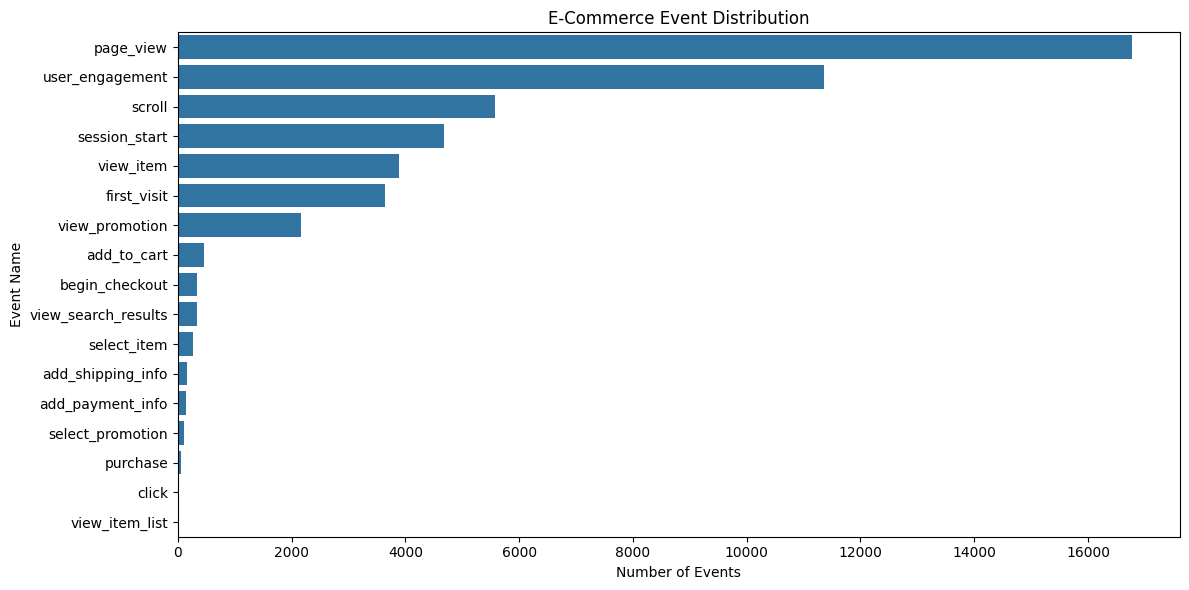

In [10]:
plt.figure(figsize=(12, 6))

sns.barplot(
    data=event_counts,
    x="Event_Count",
    y="Event_Name"
)

plt.title("E-Commerce Event Distribution")
plt.xlabel("Number of Events")
plt.ylabel("Event Name")
plt.tight_layout()
plt.show()

### 3: Device Behaviour Analysis

In [11]:
device_events = (
    df.groupby("device_category")
    .size()
    .reset_index(name="Event_Count")
    .sort_values("Event_Count", ascending=False)
)

device_events

,device_category,Event_Count
0,desktop,29156
1,mobile,19716
2,tablet,1128


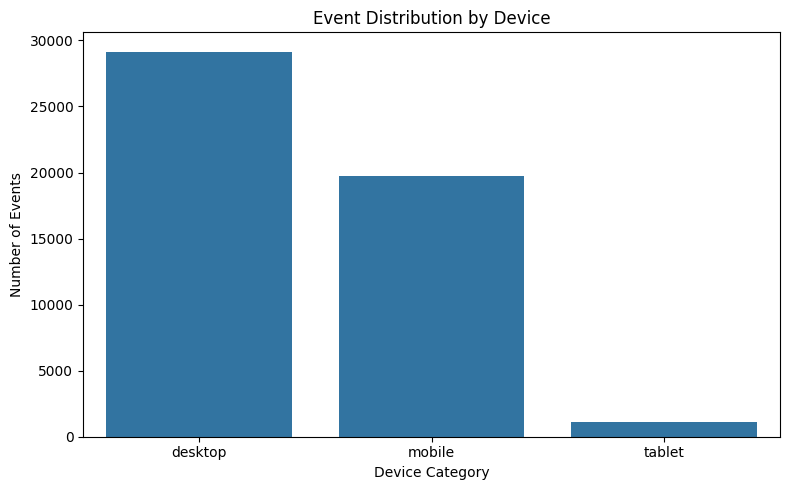

In [12]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=device_events,
    x="device_category",
    y="Event_Count"
)

plt.title("Event Distribution by Device")
plt.xlabel("Device Category")
plt.ylabel("Number of Events")

plt.tight_layout()
plt.show()

In [13]:
device_users = (
    df.groupby("device_category")["user_pseudo_id"]
    .nunique()
    .reset_index(name="Unique_Users")
)

device_users

,device_category,Unique_Users
0,desktop,16064
1,mobile,11073
2,tablet,668


In [14]:
device_purchases = (
    df[df["event_name"] == "purchase"]
    .groupby("device_category")
    .size()
    .reset_index(name="Purchase_Events")
)

device_purchases

,device_category,Purchase_Events
0,desktop,34
1,mobile,23


### 4: Traffic Source Analysis

In [15]:
# Include missing traffic sources
traffic_sources = (
    df.groupby("traffic_source", dropna=False)
    .size()
    .reset_index(name="Event_Count")
    .sort_values("Event_Count", ascending=False)
)

traffic_sources["traffic_source"] = (
    traffic_sources["traffic_source"]
    .fillna("Unknown")
)

traffic_sources

,traffic_source,Event_Count
2,google,17757
1,<Other>,13397
0,(direct),11733
3,shop.googlemerchandisestore.com,3921
4,Unknown,3192


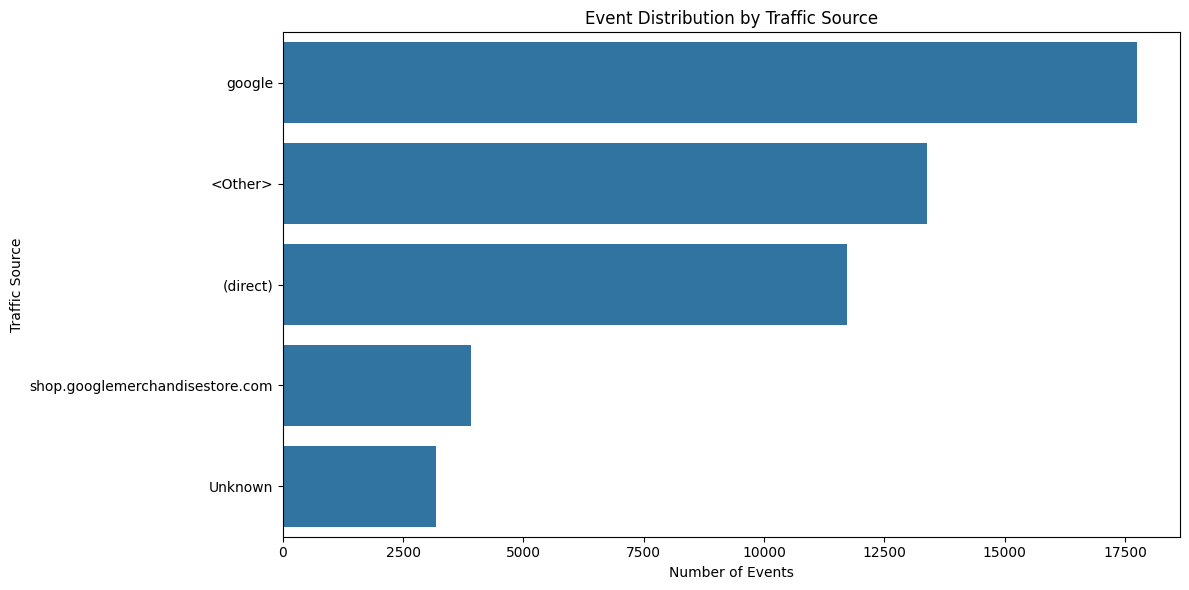

In [16]:
plt.figure(figsize=(12, 6))

sns.barplot(
    data=traffic_sources,
    x="Event_Count",
    y="traffic_source"
)

plt.title("Event Distribution by Traffic Source")
plt.xlabel("Number of Events")
plt.ylabel("Traffic Source")

plt.tight_layout()
plt.show()

In [17]:
traffic_medium = (
    df.groupby("traffic_medium")
    .size()
    .reset_index(name="Event_Count")
    .sort_values("Event_Count", ascending=False)
)

traffic_medium

,traffic_medium,Event_Count
3,organic,17076
0,(none),11733
4,referral,8801
1,<Other>,7111
2,cpc,2065


In [18]:
source_purchases_complete = (
    df[df["event_name"] == "purchase"]
    .groupby("traffic_source", dropna=False)
    .size()
    .reset_index(name="Purchase_Events")
    .sort_values("Purchase_Events", ascending=False)
)

source_purchases_complete["traffic_source"] = (
    source_purchases_complete["traffic_source"]
    .fillna("Unknown")
)

source_purchases_complete

,traffic_source,Purchase_Events
2,google,20
1,<Other>,16
3,shop.googlemerchandisestore.com,8
4,Unknown,8
0,(direct),5


### 5: Product Performance Analysis

In [19]:
product_df = pd.read_csv(
    "../data/raw/ga4_product_events.csv",
    dtype={
        "user_pseudo_id": "string",
        "session_id": "string",
        "item_id": "string"
    }
)

print("Product Dataset Shape:", product_df.shape)

product_df.head()

Product Dataset Shape: (50000, 13)


,event_date,event_name,user_pseudo_id,device_category,traffic_source,traffic_medium,session_id,item_id,item_name,item_category,quantity,price,purchase_revenue
0,20210131,view_item,1540124.2144280285,desktop,google,organic,5349214666,GGOEAFBA115599,Android Super Hero 3D Framed Art,NaN,NaN,40.0,NaN
1,20210131,add_to_cart,1540124.2144280285,desktop,google,organic,5349214666,9190330,Google Crew Socks,NaN,1.0,16.0,NaN
2,20210131,view_item,1540124.2144280285,desktop,google,organic,5349214666,GGOEGAEB105210,Google Crew Socks,NaN,NaN,16.0,NaN
3,20210131,view_item,1540124.2144280285,desktop,google,organic,5349214666,GGOEAFBA115499,Android Techie 3D Framed Art,NaN,NaN,40.0,NaN
4,20210131,purchase,1617434.1535145542,mobile,google,organic,3795921985,(not set),(not set),(not set),NaN,NaN,NaN


In [20]:
product_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 13 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   event_date        50000 non-null  int64  
 1   event_name        50000 non-null  str    
 2   user_pseudo_id    50000 non-null  string 
 3   device_category   50000 non-null  str    
 4   traffic_source    50000 non-null  str    
 5   traffic_medium    50000 non-null  str    
 6   session_id        50000 non-null  string 
 7   item_id           50000 non-null  string 
 8   item_name         50000 non-null  str    
 9   item_category     49676 non-null  str    
 10  quantity          783 non-null    float64
 11  price             49979 non-null  float64
 12  purchase_revenue  234 non-null    float64
dtypes: float64(3), int64(1), str(6), string(3)
memory usage: 10.7 MB


In [21]:
product_df.isnull().sum()

event_date              0
event_name              0
user_pseudo_id          0
device_category         0
traffic_source          0
traffic_medium          0
session_id              0
item_id                 0
item_name               0
item_category         324
quantity            49217
price                  21
purchase_revenue    49766
dtype: int64

In [22]:
product_df["event_name"].value_counts()

event_name
view_item      41222
add_to_cart     8523
purchase         255
Name: count, dtype: int64

In [23]:
product_df[
    ["item_id", "item_name", "item_category"]
].value_counts().head(15)

item_id         item_name                               item_category               
GGOEGXXX0905    Google Tee Yellow                       Home/Sale/                      571
GGOEAFKA087599  Android Large Removable Sticker Sheet   Home/Sale/                      551
GGOEGXXX1344    Google Navy Speckled Tee                Home/Apparel/Men's / Unisex/    543
GGOEAFBA115599  Android Super Hero 3D Framed Art        Home/Sale/                      534
GGOEAFBA115299  Candy Cane Android Cardboard Sculpture  Home/Sale/                      532
GGOEGOCL092999  Google Small Standard Journal Navy      Home/Sale/                      531
GGOEACBA104599  Android SM S/F18 Sticker Sheet          Home/Sale/                      527
GGOEAOCB092899  Android Small Trace Journal Black       Home/Sale/                      527
GGOEAOCB092799  Android Large Trace Journal Black       Home/Sale/                      526
GGOEAFBA115499  Android Techie 3D Framed Art            Home/Sale/                     

### Top Performing Products

In [25]:
# 10 most viewed products
viewed_products = (
    product_df[
        (product_df["event_name"] == "view_item") &
        (product_df["item_name"].notna()) &
        (product_df["item_name"] != "(not set)")
    ]
    .groupby("item_name")
    .size()
    .reset_index(name="View_Count")
    .sort_values("View_Count", ascending=False)
    .head(10)
)

viewed_products

,item_name,View_Count
377,Super G Unisex Joggers,1038
117,Google Cloud Unisex Zip Hoodie,914
296,Google Sherpa Zip Hoodie Charcoal,707
364,Google Zip Hoodie F/C,701
300,Google Small Standard Journal Navy,693
19,Android Iconic Crewneck Sweatshirt,677
136,Google Crewneck Sweatshirt Green,636
304,Google Split Seam Tee Olive,621
31,Android Large Removable Sticker Sheet,605
48,Candy Cane Android Cardboard Sculpture,602


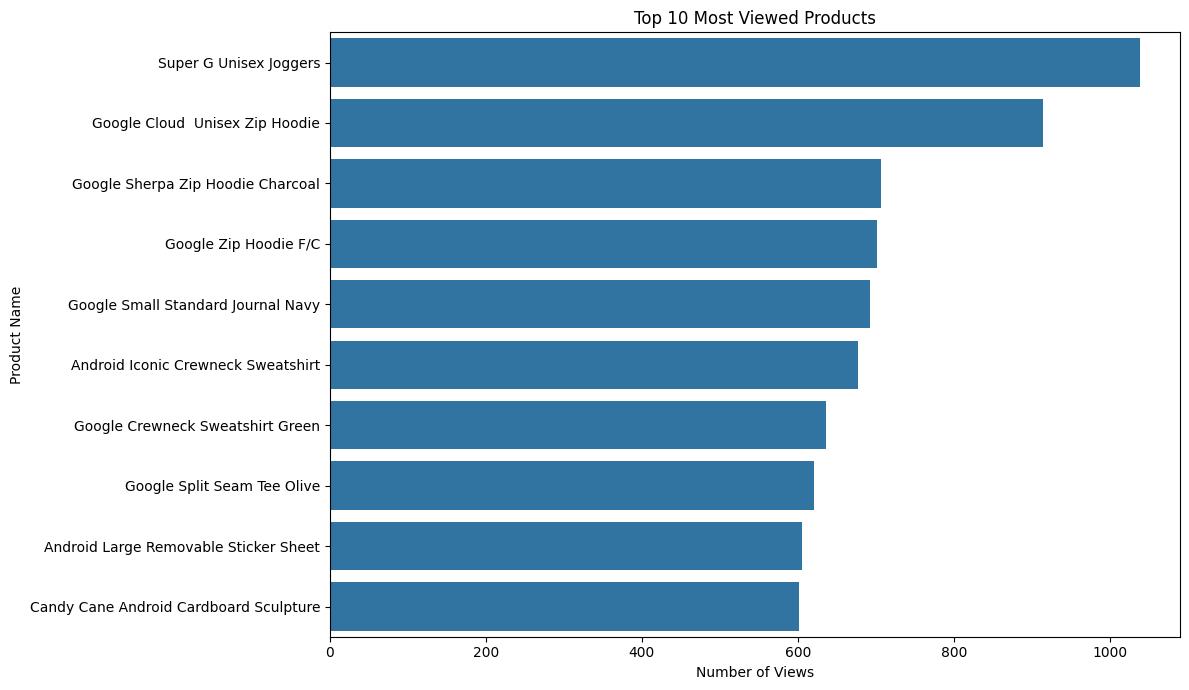

In [26]:
# Visualize top 10 viewed products
plt.figure(figsize=(12, 7))

sns.barplot(
    data=viewed_products,
    x="View_Count",
    y="item_name"
)

plt.title("Top 10 Most Viewed Products")
plt.xlabel("Number of Views")
plt.ylabel("Product Name")

plt.tight_layout()
plt.show()

In [27]:
#Top 10 products added to cart
cart_products = (
    product_df[
        (product_df["event_name"] == "add_to_cart") &
        (product_df["item_name"].notna()) &
        (product_df["item_name"] != "(not set)")
    ]
    .groupby("item_name")
    .size()
    .reset_index(name="Add_To_Cart_Count")
    .sort_values("Add_To_Cart_Count", ascending=False)
    .head(10)
)

cart_products

,item_name,Add_To_Cart_Count
282,Super G Unisex Joggers,222
93,Google Cloud Unisex Zip Hoodie,220
228,Google Small Standard Journal Navy,168
111,Google Crewneck Sweatshirt Green,160
272,Google Zip Hoodie F/C,160
231,Google Split Seam Tee Olive,156
28,Android Large Removable Sticker Sheet,143
261,Google Women's Striped L/S,143
224,Google Sherpa Zip Hoodie Charcoal,143
42,Candy Cane Android Cardboard Sculpture,141


In [28]:
#Top 10 purchased products
purchased_products = (
    product_df[
        (product_df["event_name"] == "purchase") &
        (product_df["item_name"].notna()) &
        (product_df["item_name"] != "(not set)")
    ]
    .groupby("item_name")
    .size()
    .reset_index(name="Purchase_Count")
    .sort_values("Purchase_Count", ascending=False)
    .head(10)
)

purchased_products

,item_name,Purchase_Count
126,Google Unisex Eco Tee Black,11
36,Google Crew Socks,8
14,Google Black Cloud Zip Hoodie,7
30,Google Clear Pen 4-Pack,6
81,Google Metallic Notebook Set,6
136,Super G Unisex Joggers,6
37,Google Crewneck Sweatshirt Green,6
107,Google Sherpa Zip Hoodie Navy,5
75,Google Magnet,4
106,Google See-No Hear-No Set,4


### 6. Conversion Funnel Analysis

In [29]:
#Filter relevant events
funnel_events = [
    "view_item",
    "add_to_cart",
    "begin_checkout",
    "purchase"
]

funnel_df = df[
    df["event_name"].isin(funnel_events)
].copy()

funnel_df["event_name"].value_counts()

event_name
view_item         3884
add_to_cart        465
begin_checkout     344
purchase            57
Name: count, dtype: int64

In [30]:
funnel_df["session_key"] = (
    funnel_df["user_pseudo_id"].astype("string")
    + "_"
    + funnel_df["session_id"].astype("string")
)

In [31]:
session_funnel = (
    funnel_df
    .groupby("event_name")["session_key"]
    .nunique()
    .reindex(funnel_events, fill_value=0)
    .reset_index()
)

session_funnel.columns = [
    "Funnel_Stage",
    "Unique_Sessions"
]

session_funnel

,Funnel_Stage,Unique_Sessions
0,view_item,2787
1,add_to_cart,394
2,begin_checkout,295
3,purchase,57


In [32]:
session_funnel["Conversion_Rate"] = (
    session_funnel["Unique_Sessions"] /
    session_funnel.loc[0, "Unique_Sessions"]
) * 100

session_funnel["Drop_Off"] = (
    session_funnel["Unique_Sessions"].shift(1) -
    session_funnel["Unique_Sessions"]
)

session_funnel["Drop_Off_Rate"] = (
    session_funnel["Drop_Off"] /
    session_funnel["Unique_Sessions"].shift(1)
) * 100

session_funnel

,Funnel_Stage,Unique_Sessions,Conversion_Rate,Drop_Off,Drop_Off_Rate
0,view_item,2787,100.000000,NaN,NaN
1,add_to_cart,394,14.137065,2393.0,85.862935
2,begin_checkout,295,10.584858,99.0,25.126904
3,purchase,57,2.045210,238.0,80.677966


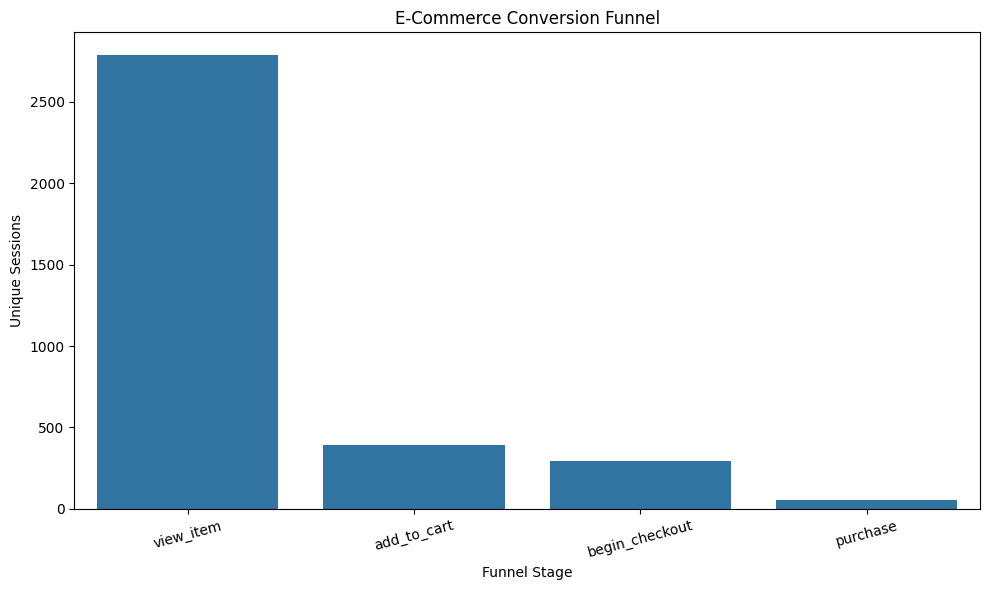

In [33]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=session_funnel,
    x="Funnel_Stage",
    y="Unique_Sessions"
)

plt.title("E-Commerce Conversion Funnel")
plt.xlabel("Funnel Stage")
plt.ylabel("Unique Sessions")

plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

In [34]:
dropoff_analysis = session_funnel.iloc[1:].copy()

biggest_dropoff = dropoff_analysis.loc[
    dropoff_analysis["Drop_Off_Rate"].idxmax()
]

print("Biggest Drop-off Stage:",
      biggest_dropoff["Funnel_Stage"])

print("Drop-off Rate:",
      round(biggest_dropoff["Drop_Off_Rate"], 2), "%")

Biggest Drop-off Stage: add_to_cart
Drop-off Rate: 85.86 %


In [35]:
# Sort events chronologically within each session
funnel_df = funnel_df.sort_values(
    ["session_key", "event_timestamp"]
)

# Function to check sequential funnel progression
def check_funnel_sequence(group):

    events = group["event_name"].tolist()

    stages = [
        "view_item",
        "add_to_cart",
        "begin_checkout",
        "purchase"
    ]

    stage_index = 0

    for event in events:
        if event == stages[stage_index]:
            stage_index += 1

            if stage_index == len(stages):
                break

    return stage_index


# Calculate the furthest stage reached by each session
session_progress = (
    funnel_df.groupby("session_key")
    .apply(check_funnel_sequence)
)

# Count sessions reaching each sequential stage
sequential_funnel = pd.DataFrame({
    "Funnel_Stage": [
        "view_item",
        "add_to_cart",
        "begin_checkout",
        "purchase"
    ],
    "Unique_Sessions": [
        (session_progress >= 1).sum(),
        (session_progress >= 2).sum(),
        (session_progress >= 3).sum(),
        (session_progress >= 4).sum()
    ]
})

sequential_funnel

,Funnel_Stage,Unique_Sessions
0,view_item,2787
1,add_to_cart,124
2,begin_checkout,18
3,purchase,0
